In [3]:
# reload modules before execution (for the changing code in Src)
%load_ext autoreload
%autoreload 2

In [4]:
import numpy as np

import matplotlib.pyplot as plt

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import plotting_tools

from scipy.special import gamma

In [5]:
rng = np.random.default_rng()

In [6]:
# population correlation
rho = 0.6
# number of data points in a vector
n = 20
# number of generated pairs
d = 1000000

# bivariate normal distribution
Sigma = np.array([[1, rho],[rho, 1]])
mu = np.array([1, 1])

# two correlated vectors
data = rng.multivariate_normal(mean=mu, cov=Sigma, size=(d,n))
X = data[:,:,0].T
Y = data[:,:,1].T

In [7]:
'''
# This code doesn't produce results because R array is too large for allocation
# for d which can produce smooth-ish histogram
tilde_X = X - X.mean(axis=0)
tilde_Y = Y - Y.mean(axis=0)

U = tilde_X / np.linalg.norm(tilde_X, axis = 0, keepdims=True)
V = tilde_Y / np.linalg.norm(tilde_Y, axis = 0, keepdims=True)

R = U.T @ V

R_paired = np.diag(R)
R_indep = R[~np.eye(d, dtype=bool)].ravel()
'''
tilde_X = X - X.mean(axis=0)
tilde_Y = Y - Y.mean(axis=0)

R_paired = np.sum(tilde_X * tilde_Y, axis=0) / np.sqrt(np.sum(tilde_X**2, axis=0) * np.sum(tilde_Y**2, axis=0))

q025, q975 = np.quantile(R_paired, [0.025, 0.975])
print(q025, q975)

0.2313258050799846 0.8292769585821307


In [8]:
from scipy.special import gammaln, hyp2f1
def fisher_r_pdf(r: float, n: int, rho: float):
    c = (n - 2)/np.sqrt(2 * np.pi)
    ln_g = gammaln(n - 1) - gammaln(n - 0.5)
    ln_rho = (n-1)/2 * (np.log1p(rho) + np.log1p(-rho))
    ln_r = (n-4)/2 * (np.log1p(r) + np.log1p(-r))
    ln_rhor = (n - 3/2) * np.log1p(-rho*r)
    return c * np.exp(ln_g + ln_rho + ln_r - ln_rhor) * hyp2f1(0.5, 0.5, n - 0.5, 0.5*(1 + r * rho))

In [9]:
from scipy.integrate import quad
def fisher_r_cdf(r: float, n: int, rho: float):
    return quad(
        fisher_r_pdf,
        -1, r,
        args=(n, rho),
        epsabs=1e-11,
        limit=300
    )[0]

In [10]:
from scipy.optimize import brentq
def fisher_r_ppf(p, n, rho):
    return brentq(
        lambda r: fisher_r_cdf(r, n, rho) - p,
        -1, 1
    )

In [22]:
q_025_exact = fisher_r_ppf(0.025, n, rho)
q_975_exact = fisher_r_ppf(0.975, n, rho)
print(q_025_exact, q_975_exact)

0.2315234595755249 0.8290358973590947


In [12]:
def normal_fisher_r_approx(r: float, n: int, rho: float):
    c = np.sqrt(n-3)/(np.sqrt(2 * np.pi) * (1-r**2))
    d = -(n-3)/(2)
    return c * np.exp(d * (np.arctanh(r) - np.arctanh(rho))**2)

In [17]:
from scipy.stats import norm
def normal_fisher_r_cdf(r: float, n: int, rho: float):
    if n <= 3:
        raise ValueError("n must be greater than 3")
    if not -1 < rho < 1:
        raise ValueError("rho must be strictly between -1 and 1")

    if r <= -1:
        return 0.0
    if r >= 1:
        return 1.0

    z = np.sqrt(n - 3) * (
        np.arctanh(r) - np.arctanh(rho)
    )
    return norm.cdf(z)


def normal_fisher_r_ppf(p: float, n: int, rho: float):
    if n <= 3:
        raise ValueError("n must be greater than 3")
    if not -1 < rho < 1:
        raise ValueError("rho must be strictly between -1 and 1")
    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1")

    return np.tanh(
        np.arctanh(rho)
        + norm.ppf(p) / np.sqrt(n - 3)
    )

In [23]:
q_025_norm = normal_fisher_r_ppf(0.025, n, rho)
q_975_norm = normal_fisher_r_ppf(0.975, n, rho)
print(q_025_norm, q_975_norm)

0.21440693172348954 0.8237933702349465


In [19]:
pdf_to_plot_exact_pearson_rho_0 = lambda x: gamma((n-1)/2)/(np.sqrt(np.pi)*gamma((n-2)/2))*(1-x**2)**((n-4)/2)
pdf_to_plot_fisher_r_rho = lambda r: fisher_r_pdf(n=n, rho=rho, r=r)
pdf_to_plot_normal_fisher_r = lambda r: normal_fisher_r_approx(n=n, rho=rho, r=r)

density_fn = [(pdf_to_plot_fisher_r_rho, 'black', f'exact density\n$\\rho={rho}$', '-'), 
              (pdf_to_plot_normal_fisher_r, 'fuchsia', 'normal approximation\nusing Fisher transformation', (0, (6, 8))),
             ]

In [20]:
folder = Path("../../posts/fisher_exact").resolve()
fn = folder / "fisher_exact.svg"

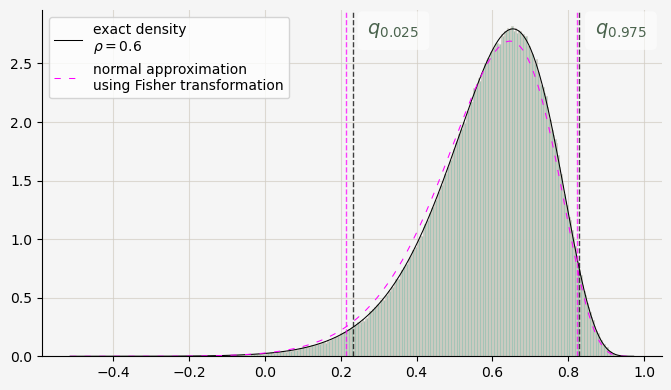

In [21]:
plotting_tools.pretty_histogram(R_paired, density = True,
                                density_fn=density_fn,
                                vertical_lines=[(q_025_exact, 'black'), (q_975_exact, 'black'),
                                              #(q025, 'teal'), (q975, 'teal'),
                                               (q_025_norm, 'fuchsia'), (q_975_norm, 'fuchsia')],
                                annotation=[{
                                    "bbox": {
                                            "boxstyle": "round,pad=0.5,rounding_size=0.25",
                                            "fc": "white",          # fill color
                                            "ec": "none",
                                            #"ec": "#a5c4b6",
                                            #"lw": 1,
                                            "alpha": 0.6
                                    },
                                    "text": '$q_{0.025}$',
                                    "xy": (0.2, 2.75),
                                    "xytext": (0.27, 2.75),
                                    "color": "#4a634d",
                                    "fontsize": 14
                                    },
                                    {
                                        "bbox": {
                                                "boxstyle": "round,pad=0.5,rounding_size=0.25",
                                                "fc": "white",          # fill color
                                                "ec": "none",
                                                #"ec": "#a5c4b6",
                                                #"lw": 1,
                                                "alpha": 0.6
                                        },
                                        "text": '$q_{0.975}$',
                                        "xy": (0.2, 2.75),
                                        "xytext": (0.87, 2.75),
                                        "color": "#4a634d",
                                        "fontsize": 14
                                    }],
                                save_file_name=fn)